In [1]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 设置数据和结果目录
project_dir = r"D:\AI-Internship\Week03_Kaggle_Tabular"
data_dir = os.path.join(project_dir, "data", "house_prices")
results_dir = os.path.join(project_dir, "results")
fig_dir = os.path.join(results_dir, "figures")

os.makedirs(fig_dir, exist_ok=True)

# 读取训练集和测试集
train = pd.read_csv(os.path.join(data_dir, "train.csv"))
test = pd.read_csv(os.path.join(data_dir, "test.csv"))

print("训练集形状：", train.shape)
print("测试集形状：", test.shape)

print("\n训练集前五行：")
display(train.head())

# 检查数据类型
print("\n数值特征数量：", train.select_dtypes(include=np.number).shape[1])
print("类别特征数量：", train.select_dtypes(include=["object", "category"]).shape[1])

# 检查缺失值
train_missing = train.isnull().sum().sort_values(ascending=False)
test_missing = test.isnull().sum().sort_values(ascending=False)

print("\n训练集缺失值最多的15列：")
display(train_missing[train_missing > 0].head(15).to_frame("Missing"))

print("\n测试集缺失值最多的15列：")
display(test_missing[test_missing > 0].head(15).to_frame("Missing"))

# 检查重复行
print("\n训练集重复行数：", train.duplicated().sum())
print("测试集重复行数：", test.duplicated().sum())

# 目标变量统计
print("\nSalePrice 统计：")
display(train["SalePrice"].describe())


训练集形状： (1460, 81)
测试集形状： (1459, 80)

训练集前五行：


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000



数值特征数量： 38
类别特征数量： 43

训练集缺失值最多的15列：


C:\Users\ROG\AppData\Local\Temp\ipykernel_25228\2542926472.py:27: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print("类别特征数量：", train.select_dtypes(include=["object", "category"]).shape[1])


,Missing
PoolQC,1453
MiscFeature,1406
Alley,1369
Fence,1179
MasVnrType,872
FireplaceQu,690
LotFrontage,259
GarageQual,81
GarageFinish,81
GarageType,81



测试集缺失值最多的15列：


,Missing
PoolQC,1456
MiscFeature,1408
Alley,1352
Fence,1169
MasVnrType,894
FireplaceQu,730
LotFrontage,227
GarageYrBlt,78
GarageCond,78
GarageFinish,78



训练集重复行数： 0
测试集重复行数： 0

SalePrice 统计：


count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

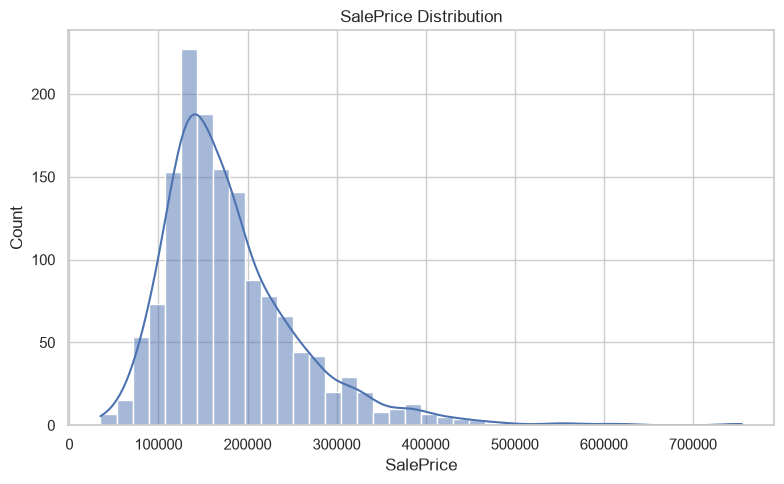

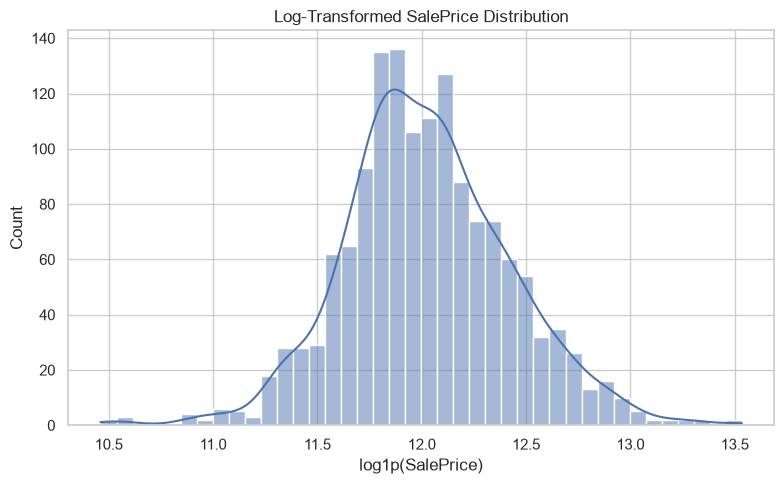

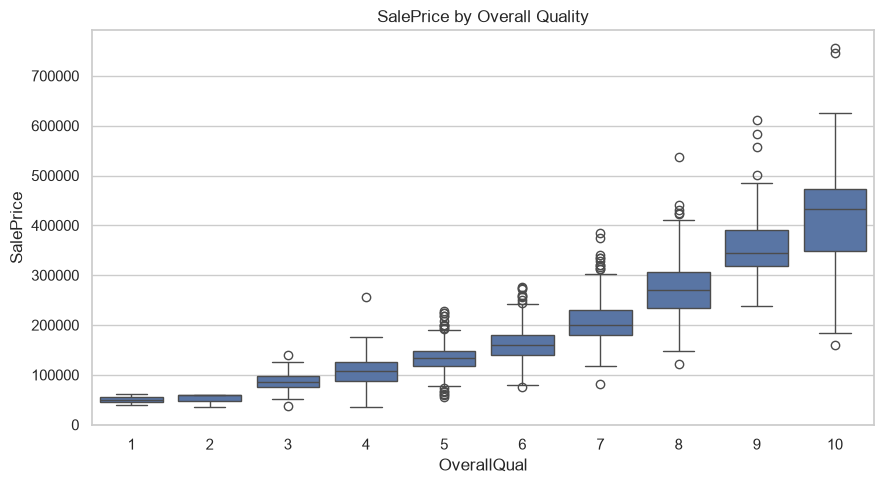

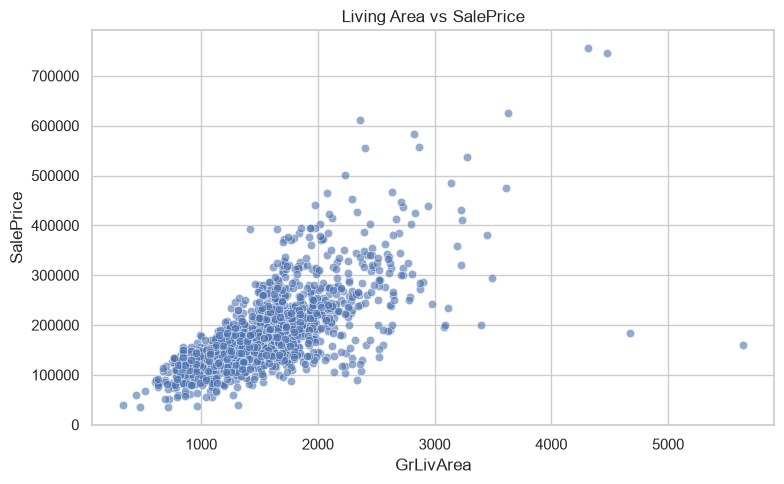

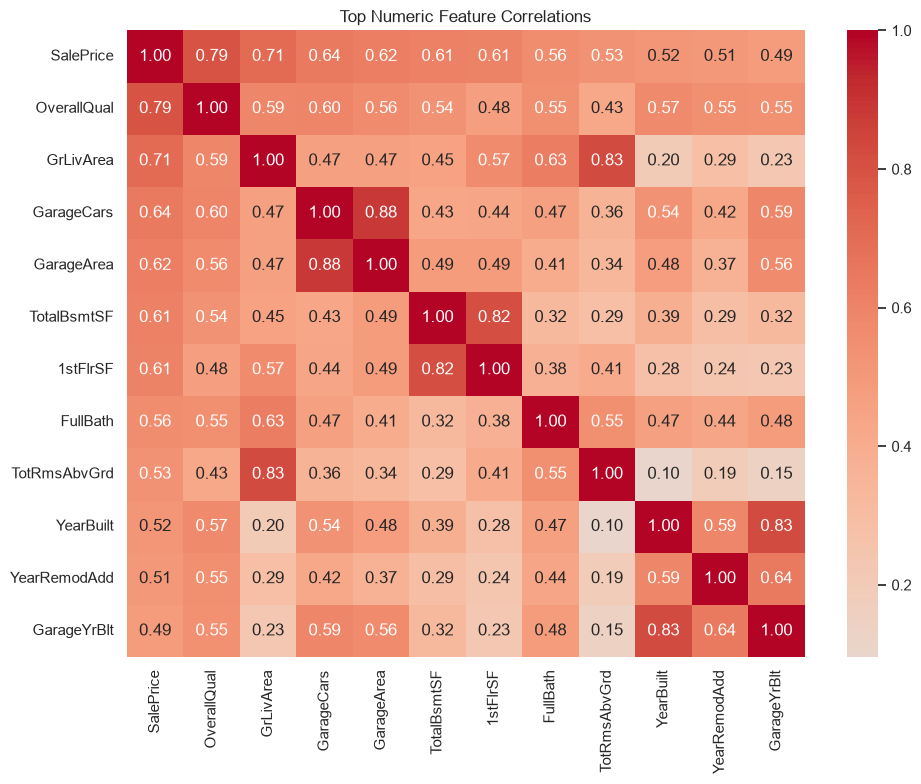

5张 House Prices EDA 图片已保存


In [2]:

# 设置图表主题
sns.set_theme(style="whitegrid")

# 房价原始分布
plt.figure(figsize=(8, 5))
sns.histplot(train["SalePrice"], bins=40, kde=True)
plt.title("SalePrice Distribution")
plt.xlabel("SalePrice")
plt.tight_layout()
plt.savefig(os.path.join(fig_dir, "house_saleprice_distribution.png"), dpi=300)
plt.show()

# 房价对数变换后的分布
plt.figure(figsize=(8, 5))
sns.histplot(np.log1p(train["SalePrice"]), bins=40, kde=True)
plt.title("Log-Transformed SalePrice Distribution")
plt.xlabel("log1p(SalePrice)")
plt.tight_layout()
plt.savefig(os.path.join(fig_dir, "house_log_saleprice_distribution.png"), dpi=300)
plt.show()

# 房屋整体质量与房价
plt.figure(figsize=(9, 5))
sns.boxplot(data=train, x="OverallQual", y="SalePrice")
plt.title("SalePrice by Overall Quality")
plt.tight_layout()
plt.savefig(os.path.join(fig_dir, "house_quality_vs_price.png"), dpi=300)
plt.show()

# 房屋居住面积与房价
plt.figure(figsize=(8, 5))
sns.scatterplot(data=train, x="GrLivArea", y="SalePrice", alpha=0.6)
plt.title("Living Area vs SalePrice")
plt.tight_layout()
plt.savefig(os.path.join(fig_dir, "house_area_vs_price.png"), dpi=300)
plt.show()

# 主要数值特征相关性
corr = train.select_dtypes(include=np.number).corr()
top_features = corr["SalePrice"].abs().sort_values(ascending=False).head(12).index

plt.figure(figsize=(10, 8))
sns.heatmap(
    train[top_features].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)
plt.title("Top Numeric Feature Correlations")
plt.tight_layout()
plt.savefig(os.path.join(fig_dir, "house_correlation_heatmap.png"), dpi=300)
plt.show()

print("5张 House Prices EDA 图片已保存")


In [3]:

from sklearn.model_selection import train_test_split

# 构建房屋特征
def build_house_features(df):
    X = df.drop(columns=["Id", "SalePrice"], errors="ignore").copy()

    # 将房屋类型编号作为类别特征
    X["MSSubClass"] = X["MSSubClass"].astype(str)

    # 构建面积相关特征
    X["TotalSF"] = (
        X["TotalBsmtSF"].fillna(0)
        + X["1stFlrSF"].fillna(0)
        + X["2ndFlrSF"].fillna(0)
    )

    X["TotalBathrooms"] = (
        X["FullBath"].fillna(0)
        + 0.5 * X["HalfBath"].fillna(0)
        + X["BsmtFullBath"].fillna(0)
        + 0.5 * X["BsmtHalfBath"].fillna(0)
    )

    # 构建房龄和翻新相关特征
    X["HouseAge"] = (
        X["YrSold"] - X["YearBuilt"]
    ).clip(lower=0)

    X["YearsSinceRemodel"] = (
        X["YrSold"] - X["YearRemodAdd"]
    ).clip(lower=0)

    return X

# 创建特征数据
X = build_house_features(train)
X_kaggle = build_house_features(test)

# 对销售价格进行 log1p 变换
y = np.log1p(train["SalePrice"])

# 划分训练集和独立验证集
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("训练集：", X_train.shape)
print("验证集：", X_val.shape)
print("Kaggle测试集：", X_kaggle.shape)

print("\n原始 SalePrice 均值：", round(train["SalePrice"].mean(), 2))
print("对数 SalePrice 均值：", round(y.mean(), 4))

print("\n新增特征：")
display(
    X_train[
        ["TotalSF", "TotalBathrooms", "HouseAge", "YearsSinceRemodel"]
    ].head()
)


训练集： (1168, 83)
验证集： (292, 83)
Kaggle测试集： (1459, 83)

原始 SalePrice 均值： 180921.2
对数 SalePrice 均值： 12.0241

新增特征：


,TotalSF,TotalBathrooms,HouseAge,YearsSinceRemodel
254,2628,2.0,53,53
1066,2370,2.5,16,15
638,1592,1.0,98,58
799,2499,2.5,70,57
380,2717,2.0,86,60


In [4]:

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# 具有“无对应设施”含义的字段
none_features = [
    "Alley", "BsmtQual", "BsmtCond", "BsmtExposure",
    "BsmtFinType1", "BsmtFinType2", "FireplaceQu",
    "GarageType", "GarageFinish", "GarageQual",
    "GarageCond", "PoolQC", "Fence", "MiscFeature",
    "MasVnrType"
]

# 填补表示没有设施的缺失值
class HouseFeatureCleaner(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()
        for col in none_features:
            if col in X.columns:
                X[col] = X[col].astype("object").fillna("None")
        return X

# 选择数值和类别特征
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = [
    col for col in X_train.columns
    if col not in numeric_features
]

# 构建数值预处理
numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(
        strategy="median",
        add_indicator=True
    )),
    ("scaler", StandardScaler())
])

# 构建类别预处理
categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(
        strategy="most_frequent"
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# 整合预处理流程
house_preprocessor = Pipeline([
    ("cleaner", HouseFeatureCleaner()),
    ("columns", ColumnTransformer([
        ("numeric", numeric_pipe, numeric_features),
        ("categorical", categorical_pipe, categorical_features)
    ]))
])

# 使用训练集拟合预处理器
X_train_processed = house_preprocessor.fit_transform(X_train)

# 验证集和测试集只执行转换
X_val_processed = house_preprocessor.transform(X_val)
X_kaggle_processed = house_preprocessor.transform(X_kaggle)

# 检查处理后的数据
print("训练集处理后：", X_train_processed.shape)
print("验证集处理后：", X_val_processed.shape)
print("Kaggle测试集处理后：", X_kaggle_processed.shape)

print("\n训练集缺失值：", np.isnan(X_train_processed).sum())
print("验证集缺失值：", np.isnan(X_val_processed).sum())
print("测试集缺失值：", np.isnan(X_kaggle_processed).sum())

print("\n所有数据均为有限数值：",
      np.isfinite(X_train_processed).all()
      and np.isfinite(X_val_processed).all()
      and np.isfinite(X_kaggle_processed).all())


训练集处理后： (1168, 321)
验证集处理后： (292, 321)
Kaggle测试集处理后： (1459, 321)

训练集缺失值： 0
验证集缺失值： 0
测试集缺失值： 0

所有数据均为有限数值： True


In [5]:

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.model_selection import KFold, cross_validate
from sklearn.linear_model import Ridge
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    HistGradientBoostingRegressor
)
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

# 定义四个回归模型
models = {
    "Ridge": Ridge(alpha=10.0),
    "Random Forest": RandomForestRegressor(
        n_estimators=150,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ),
    "HistGradientBoosting": HistGradientBoostingRegressor(
        max_iter=200,
        learning_rate=0.05,
        random_state=42
    )
}

# 设置五折交叉验证
cv = KFold(n_splits=5, shuffle=True, random_state=42)

cv_results = []
val_results = []
fitted_models = {}

for name, model in models.items():

    # 将预处理和回归模型组成完整 Pipeline
    pipeline = Pipeline([
        ("preprocess", clone(house_preprocessor)),
        ("model", clone(model))
    ])

    # 对 log1p(SalePrice) 进行交叉验证
    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "RMSE": "neg_root_mean_squared_error",
            "MAE": "neg_mean_absolute_error",
            "R2": "r2"
        },
        n_jobs=1,
        error_score="raise"
    )

    cv_results.append({
        "Model": name,
        "CV_RMSE": -scores["test_RMSE"].mean(),
        "CV_RMSE_Std": scores["test_RMSE"].std(),
        "CV_MAE": -scores["test_MAE"].mean(),
        "CV_R2": scores["test_R2"].mean()
    })

    # 使用完整训练集拟合模型
    pipeline.fit(X_train, y_train)

    # 在独立验证集上预测对数房价
    pred_log = pipeline.predict(X_val)

    # 计算对数空间的评价指标
    rmse_log = np.sqrt(mean_squared_error(y_val, pred_log))
    mae_log = mean_absolute_error(y_val, pred_log)
    r2 = r2_score(y_val, pred_log)

    # 转换为实际房价并计算 RMSLE
    actual_price = np.expm1(y_val)
    pred_price = np.expm1(pred_log).clip(min=0)

    rmsle = np.sqrt(
        mean_squared_error(
            np.log1p(actual_price),
            np.log1p(pred_price)
        )
    )

    val_results.append({
        "Model": name,
        "RMSE_log": rmse_log,
        "MAE_log": mae_log,
        "R2_log": r2,
        "RMSLE": rmsle
    })

    fitted_models[name] = pipeline
    print(f"{name} 训练与验证完成")

# 整理比较结果
cv_df = pd.DataFrame(cv_results).sort_values("CV_RMSE")
val_df = pd.DataFrame(val_results).sort_values("RMSLE")

print("\n五折交叉验证结果：")
display(cv_df.round(4))

print("\n独立验证集结果：")
display(val_df.round(4))


Ridge 训练与验证完成
Random Forest 训练与验证完成
Gradient Boosting 训练与验证完成
HistGradientBoosting 训练与验证完成

五折交叉验证结果：


,Model,CV_RMSE,CV_RMSE_Std,CV_MAE,CV_R2
2,Gradient Boosting,0.1286,0.0162,0.0864,0.8911
3,HistGradientBoosting,0.1301,0.0159,0.0890,0.8886
0,Ridge,0.1406,0.0295,0.0899,0.8675
1,Random Forest,0.1437,0.0156,0.0980,0.8641



独立验证集结果：


,Model,RMSE_log,MAE_log,R2_log,RMSLE
0,Ridge,0.1373,0.0941,0.8989,0.1373
2,Gradient Boosting,0.1375,0.0889,0.8986,0.1375
3,HistGradientBoosting,0.1392,0.0900,0.8962,0.1392
1,Random Forest,0.1461,0.0962,0.8856,0.1461


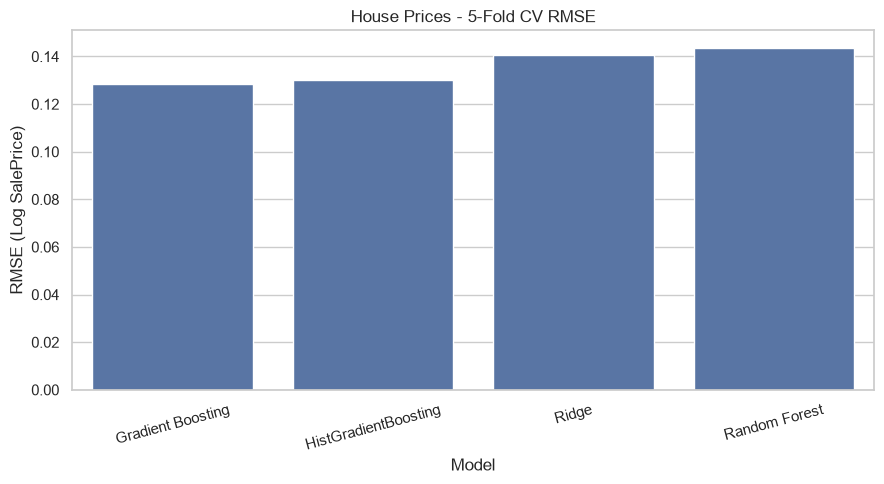

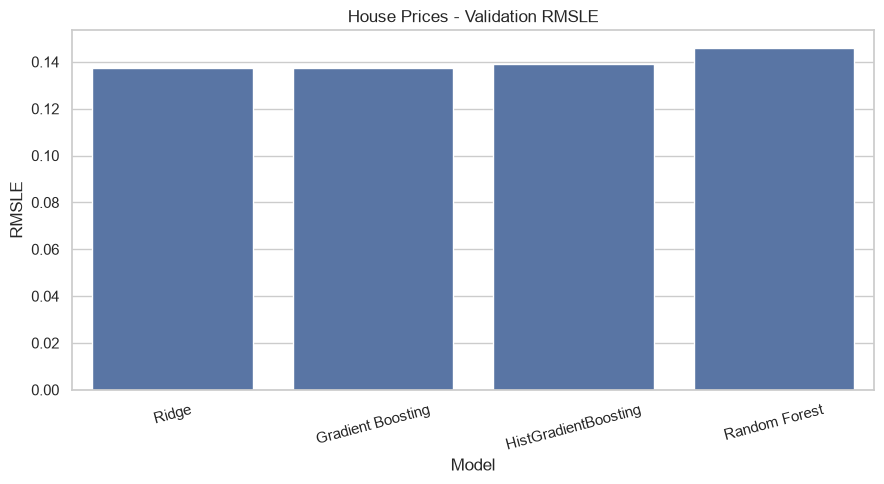

CV 最佳模型： Gradient Boosting
独立验证最佳模型： Ridge
模型比较 CSV 和 PNG 已保存


In [6]:

# 保存交叉验证与独立验证结果
cv_df.to_csv(
    os.path.join(results_dir, "house_cv_comparison.csv"),
    index=False
)

val_df.to_csv(
    os.path.join(results_dir, "house_validation_comparison.csv"),
    index=False
)

# 绘制交叉验证 RMSE 比较图
plt.figure(figsize=(9, 5))

sns.barplot(
    data=cv_df,
    x="Model",
    y="CV_RMSE",
    errorbar=None
)

plt.title("House Prices - 5-Fold CV RMSE")
plt.ylabel("RMSE (Log SalePrice)")
plt.xlabel("Model")
plt.xticks(rotation=15)
plt.tight_layout()

plt.savefig(
    os.path.join(fig_dir, "house_cv_model_comparison.png"),
    dpi=300
)
plt.show()

# 绘制独立验证集 RMSLE 比较图
plt.figure(figsize=(9, 5))

sns.barplot(
    data=val_df,
    x="Model",
    y="RMSLE",
    errorbar=None
)

plt.title("House Prices - Validation RMSLE")
plt.ylabel("RMSLE")
plt.xlabel("Model")
plt.xticks(rotation=15)
plt.tight_layout()

plt.savefig(
    os.path.join(fig_dir, "house_validation_model_comparison.png"),
    dpi=300
)
plt.show()

# 输出表现最好的模型
best_cv_model = cv_df.iloc[0]["Model"]
best_val_model = val_df.iloc[0]["Model"]

print("CV 最佳模型：", best_cv_model)
print("独立验证最佳模型：", best_val_model)
print("模型比较 CSV 和 PNG 已保存")


融合模型： Gradient Boosting + HistGradientBoosting

最终验证结果：


,Model,RMSE_log,MAE_log,R2_log,RMSLE
4,Blend (Gradient Boosting + HistGradientBoosting),0.13561,0.08587,0.90146,0.13561
0,Ridge,0.13733,0.09412,0.89894,0.13733
1,Gradient Boosting,0.13754,0.08886,0.89862,0.13754
2,HistGradientBoosting,0.13920,0.08996,0.89617,0.13920
3,Random Forest,0.14608,0.09622,0.88564,0.14608


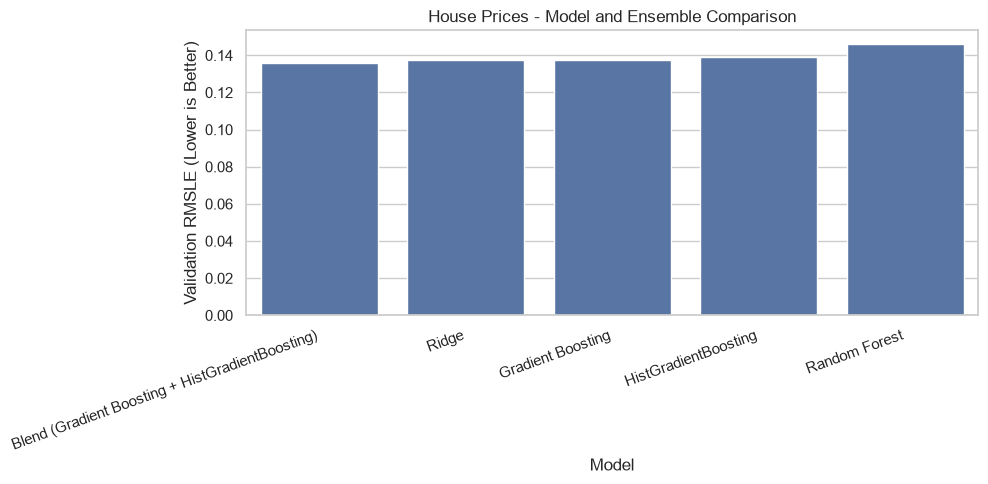

融合模型比较 CSV 和 PNG 已保存


In [7]:

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# 根据五折交叉验证结果选择两个模型
top_models = (
    cv_df.sort_values("CV_RMSE")
    .head(2)["Model"]
    .tolist()
)

model_a, model_b = top_models

# 获取两个模型的验证集预测
pred_a_log = fitted_models[model_a].predict(X_val)
pred_b_log = fitted_models[model_b].predict(X_val)

# 在对数价格空间进行等权融合
blend_log = 0.5 * pred_a_log + 0.5 * pred_b_log

# 计算融合模型指标
blend_price = np.expm1(blend_log).clip(min=0)
actual_price = np.expm1(y_val)

blend_rmsle = np.sqrt(
    mean_squared_error(
        np.log1p(actual_price),
        np.log1p(blend_price)
    )
)

blend_result = {
    "Model": f"Blend ({model_a} + {model_b})",
    "RMSE_log": np.sqrt(mean_squared_error(y_val, blend_log)),
    "MAE_log": mean_absolute_error(y_val, blend_log),
    "R2_log": r2_score(y_val, blend_log),
    "RMSLE": blend_rmsle
}

# 合并单模型与融合模型的评估结果
final_val_df = pd.concat(
    [val_df, pd.DataFrame([blend_result])],
    ignore_index=True
).sort_values("RMSLE")

# 保存融合比较结果
final_val_df.to_csv(
    os.path.join(results_dir, "house_final_model_comparison.csv"),
    index=False
)

print("融合模型：", model_a, "+", model_b)
print("\n最终验证结果：")
display(final_val_df.round(5))

# 绘制融合前后的比较图
plt.figure(figsize=(10, 5))

sns.barplot(
    data=final_val_df,
    x="Model",
    y="RMSLE",
    errorbar=None
)

plt.title("House Prices - Model and Ensemble Comparison")
plt.ylabel("Validation RMSLE (Lower is Better)")
plt.xlabel("Model")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()

plt.savefig(
    os.path.join(fig_dir, "house_ensemble_comparison.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("融合模型比较 CSV 和 PNG 已保存")


验证集表现最佳的方案： Blend (Gradient Boosting + HistGradientBoosting)
RMSE（实际价格）：29318.96
MAE（实际价格）：15633.48
R²（实际价格）：0.8879


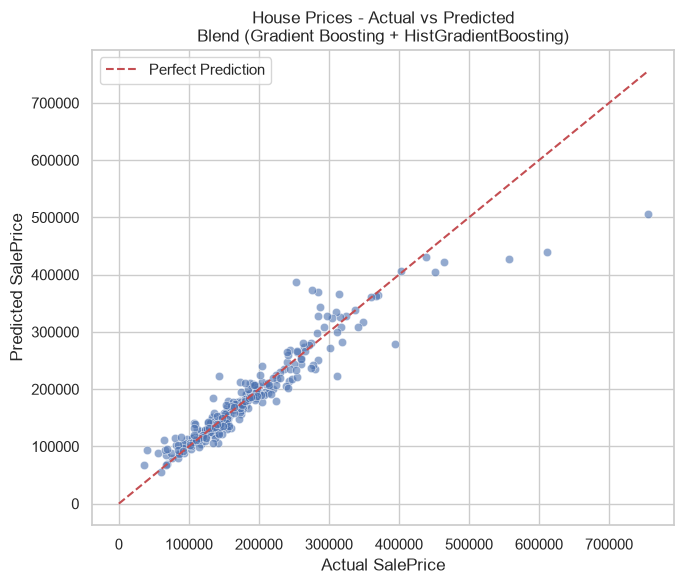

真实房价与预测房价对比图已保存


In [8]:

# 获取独立验证集表现最好的模型或融合方案
best_model_name = final_val_df.iloc[0]["Model"]

if best_model_name.startswith("Blend ("):
    best_pred_log = blend_log
else:
    best_pred_log = fitted_models[best_model_name].predict(X_val)

# 将对数价格转换回实际房价
actual_price = np.expm1(y_val)
predicted_price = np.expm1(best_pred_log).clip(min=0)

# 计算实际价格空间的评价指标
rmse_price = np.sqrt(mean_squared_error(actual_price, predicted_price))
mae_price = mean_absolute_error(actual_price, predicted_price)
r2_price = r2_score(actual_price, predicted_price)

print("验证集表现最佳的方案：", best_model_name)
print(f"RMSE（实际价格）：{rmse_price:.2f}")
print(f"MAE（实际价格）：{mae_price:.2f}")
print(f"R²（实际价格）：{r2_price:.4f}")

# 绘制真实房价与预测房价
plt.figure(figsize=(7, 6))

sns.scatterplot(
    x=actual_price,
    y=predicted_price,
    alpha=0.6
)

max_price = max(actual_price.max(), predicted_price.max())

plt.plot(
    [0, max_price],
    [0, max_price],
    "r--",
    label="Perfect Prediction"
)

plt.title(f"House Prices - Actual vs Predicted\n{best_model_name}")
plt.xlabel("Actual SalePrice")
plt.ylabel("Predicted SalePrice")
plt.legend()
plt.tight_layout()

plt.savefig(
    os.path.join(fig_dir, "house_actual_vs_predicted.png"),
    dpi=300
)
plt.show()

print("真实房价与预测房价对比图已保存")


In [9]:

from sklearn.base import clone

# 使用全部训练数据重新训练两个模型
X_full = X.copy()
y_full = y.copy()

final_models = {}

for name in top_models:
    final_model = clone(fitted_models[name])
    final_model.fit(X_full, y_full)

    final_models[name] = final_model
    print(f"{name} 全量训练完成")

# 生成第一个单模型预测
pred_1_log = final_models[model_a].predict(X_kaggle)

# 生成第二个融合预测
pred_a_log = final_models[model_a].predict(X_kaggle)
pred_b_log = final_models[model_b].predict(X_kaggle)

pred_2_log = 0.5 * pred_a_log + 0.5 * pred_b_log

# 还原实际房价并保证预测非负
pred_1 = np.expm1(pred_1_log).clip(min=0)
pred_2 = np.expm1(pred_2_log).clip(min=0)

# 创建两个 Kaggle 提交文件
submission_1 = pd.DataFrame({
    "Id": test["Id"],
    "SalePrice": pred_1
})

submission_2 = pd.DataFrame({
    "Id": test["Id"],
    "SalePrice": pred_2
})

# 验证提交文件格式
for submission in [submission_1, submission_2]:
    assert submission.shape == (1459, 2)
    assert submission["Id"].is_unique
    assert submission.notnull().all().all()
    assert np.isfinite(submission["SalePrice"]).all()
    assert (submission["SalePrice"] >= 0).all()

# 保存预测结果
path_1 = os.path.join(results_dir, "house_submission_1.csv")
path_2 = os.path.join(results_dir, "house_submission_2.csv")

submission_1.to_csv(path_1, index=False)
submission_2.to_csv(path_2, index=False)

print("\n第一次提交模型：", model_a)
print("第二次提交模型：", model_a, "+", model_b)

print("\n文件已保存：")
print(path_1)
print(path_2)

display(submission_1.head())
display(submission_2.head())


Gradient Boosting 全量训练完成
HistGradientBoosting 全量训练完成

第一次提交模型： Gradient Boosting
第二次提交模型： Gradient Boosting + HistGradientBoosting

文件已保存：
D:\AI-Internship\Week03_Kaggle_Tabular\results\house_submission_1.csv
D:\AI-Internship\Week03_Kaggle_Tabular\results\house_submission_2.csv


,Id,SalePrice
0,1461,122403.823588
1,1462,161868.983436
2,1463,179014.992354
3,1464,186953.749993
4,1465,186501.714912


,Id,SalePrice
0,1461,122028.620272
1,1462,159624.026700
2,1463,180893.480064
3,1464,188027.992906
4,1465,188282.336418
